# Homework Part A — Regression: Medical Insurance Charges

**Student:** Varshith Reddy

**Task.** Predict a person's yearly medical insurance charges (USD) from age, sex, BMI, number of children, smoking status and US region.

**Approach.** Following the class ConstraintsMLprediction example:
* a utility object holds the settings and the data helpers;
* the scaling statistics are stored inside the PyTorch model, so the ONNX graph takes raw values;
* training uses Adam (lr = 0.001), batch size 16 and a fixed number of epochs;
* R² is the main metric;
* the best model is exported to ONNX with `input1` / `output1` for onnxruntime-web on GitHub Pages.

Models are compared with **5-fold cross-validation** on the training data. The 20 % test split is used only once, at the end.

In [1]:
## Colab already has torch, pandas, sklearn and matplotlib. Uncomment if needed:
## !pip install onnx onnxruntime mlxtend

In [2]:
import os, json, copy, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from mlxtend.plotting import heatmap
import onnxruntime as rt

np.set_printoptions(suppress=True)
torch.set_printoptions(sci_mode=False)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs('figures', exist_ok=True)
os.makedirs('ONNXmodels', exist_ok=True)
print(torch.__version__, device)

2.14.1 cpu


## 1. Utility object (settings and data helpers)

In [3]:
class RegressionUtils:

    def __init__(self):
        self.random_seed   = 42
        self.test_size     = 0.20
        self.n_folds       = 5
        self.batch_size    = 16
        self.learning_rate = 0.001
        self.N_EPOCHS      = 200
        self.epsilon       = 0.0001
        self.log_target    = True        ## model learns log(charges); predictions are exponentiated back to USD

    def set_seed(self):
        random.seed(self.random_seed); np.random.seed(self.random_seed); torch.manual_seed(self.random_seed)

    def read_csv_file_with_pandas(self, url):
        self.df = pd.read_csv(url)
        return self.df

    def split_np_data_train_test(self, X, y):
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            X, y, test_size=self.test_size, random_state=self.random_seed)

    def target_transform(self, y_t):
        return torch.log(y_t) if self.log_target else y_t

    def scaling_stats(self, X, y):
        ## means / deviations from the rows the model is trained on (fold-train or full train)
        X_t = torch.tensor(X, dtype=torch.float32)
        y_t = self.target_transform(torch.tensor(y, dtype=torch.float32))
        x_means      = X_t.mean(0, keepdim=True)
        x_deviations = X_t.std(0, keepdim=True) + self.epsilon
        x_means[:, N_CONT:] = 0.0          ## 0/1 columns are left unscaled
        x_deviations[:, N_CONT:] = 1.0
        y_means      = y_t.mean(0, keepdim=True)
        y_deviations = y_t.std(0, keepdim=True) + self.epsilon
        return x_means, x_deviations, y_means, y_deviations

    def gen_Dataloader_train(self, X, y_scaled):
        ds = TensorDataset(torch.tensor(X, dtype=torch.float32), y_scaled)
        return DataLoader(ds, self.batch_size, shuffle=True, drop_last=True)   ## drop_last keeps BatchNorm happy

    def r2_score_torch(self, y_true, y_pred):
        ## same formula as the class utils: 1 - SS_res / SS_tot
        mean_true = torch.mean(y_true, dim=0, keepdim=True)
        ss_res = torch.sum((y_true - y_pred) ** 2, dim=0)
        ss_tot = torch.sum((y_true - mean_true) ** 2, dim=0)
        return 1 - ss_res / ss_tot

U = RegressionUtils()

## 2. Read the data

In [4]:
URL = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'
df = U.read_csv_file_with_pandas(URL)
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.info()
print('\nmissing values:', df.isna().sum().sum(), '| duplicate rows:', df.duplicated().sum())
df.describe(include='all').T

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

missing values: 0 | duplicate rows: 1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


## 3. Exploratory analysis

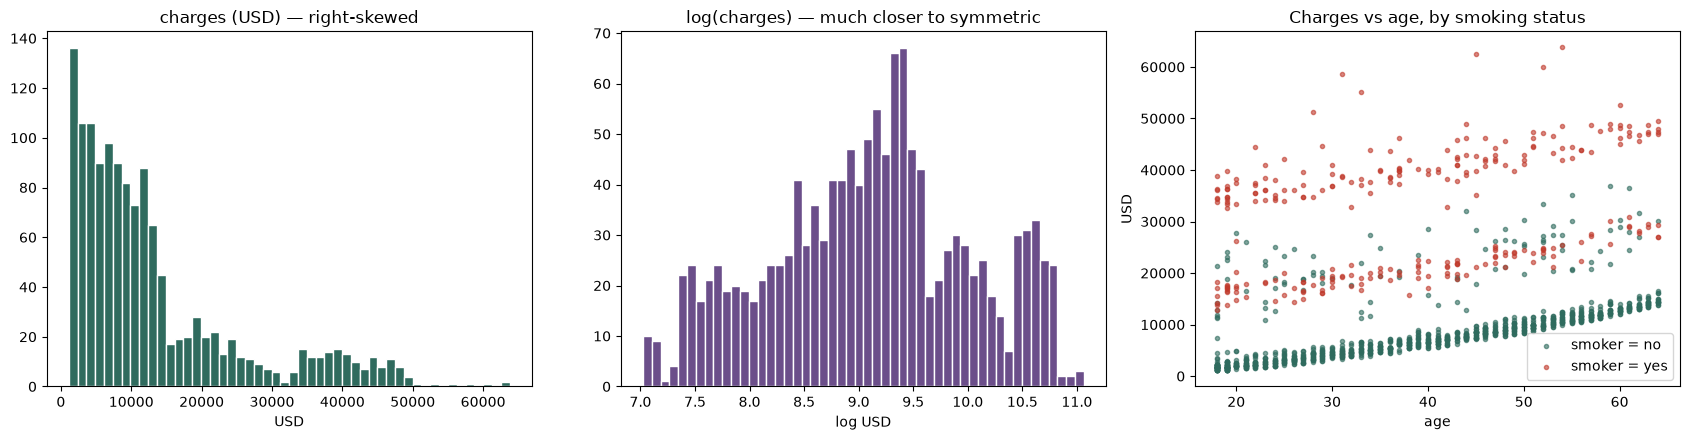

        count     mean   median
smoker                         
no       1064   8434.0   7345.0
yes       274  32050.0  34456.0

skewness of charges: 1.52 | of log(charges): -0.09


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(df.charges, bins=50, color='#2F6B5E', edgecolor='white')
axes[0].set_title('charges (USD) — right-skewed'); axes[0].set_xlabel('USD')
axes[1].hist(np.log(df.charges), bins=50, color='#6B4E8A', edgecolor='white')
axes[1].set_title('log(charges) — much closer to symmetric'); axes[1].set_xlabel('log USD')
for s, c in [('no', '#2F6B5E'), ('yes', '#C0392B')]:
    sub = df[df.smoker == s]
    axes[2].scatter(sub.age, sub.charges, s=9, alpha=0.6, c=c, label=f'smoker = {s}')
axes[2].set_title('Charges vs age, by smoking status'); axes[2].set_xlabel('age'); axes[2].set_ylabel('USD')
axes[2].legend()
plt.tight_layout(); plt.savefig('figures/A_eda.png', dpi=130); plt.show()

print(df.groupby('smoker')['charges'].agg(['count', 'mean', 'median']).round(0))
print('\nskewness of charges: %.2f | of log(charges): %.2f' % (df.charges.skew(), np.log(df.charges).skew()))

**Observations**
* Smoking dominates: smokers pay about 3.8× more on average, and they form the upper bands in the scatter plot.
* Within each group, charges rise steadily with age. There are three visible bands: non-smokers, smokers, and smokers with high BMI.
* `charges` is strongly right-skewed (skew ≈ 1.5). Taking the log makes it close to symmetric, so the model is trained on log(charges).
* The data has no missing values and one exact duplicate row, which is removed.

## 4. Preprocessing

In [7]:
df = df.drop_duplicates().reset_index(drop=True)

REGIONS  = ['northeast', 'northwest', 'southeast', 'southwest']
CONT     = ['age', 'bmi', 'children']
FEATURES = CONT + ['sex_male', 'smoker_yes'] + ['region_' + r for r in REGIONS]     ## 9 raw model inputs (ONNX order)
N_CONT, N_IN = len(CONT), len(FEATURES)

data = pd.DataFrame({'age': df.age.astype(float), 'bmi': df.bmi, 'children': df.children.astype(float),
                     'sex_male':   (df.sex == 'male').astype(float),
                     'smoker_yes': (df.smoker == 'yes').astype(float)})
for r in REGIONS:
    data['region_' + r] = (df.region == r).astype(float)
data['charges'] = df.charges

X = data[FEATURES].values.astype(np.float32)
y = data[['charges']].values.astype(np.float32)
U.split_np_data_train_test(X, y)
print('features:', FEATURES)
print('train', U.X_train.shape, '| test', U.X_test.shape)

features: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest']
train (1069, 9) | test (268, 9)


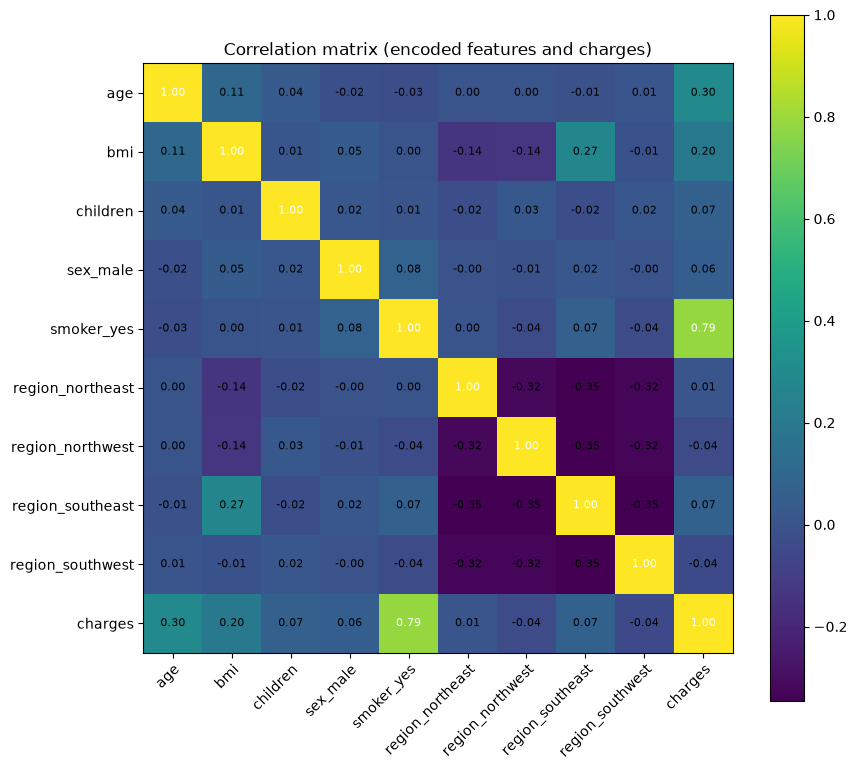

smoker_yes          0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex_male            0.058044
region_northeast    0.005945
region_northwest   -0.038695
region_southwest   -0.043637
Name: charges, dtype: float64

In [8]:
cols = FEATURES + ['charges']
corr = np.corrcoef(data[cols].values.T)
fig, ax = heatmap(corr, row_names=cols, column_names=cols, figsize=(9, 8), cell_font_size=8)
plt.title('Correlation matrix (encoded features and charges)')
plt.tight_layout(); plt.savefig('figures/A_corr.png', dpi=130); plt.show()
data[cols].corr()['charges'].drop('charges').sort_values(ascending=False)

## 5. Models

Each network is a small *core* that works on standardized inputs. A `Pipeline` module wraps it with the preprocessing:
* standardize the raw inputs with the stored means and deviations;
* run the core;
* de-scale the output, then apply `exp` to get USD back.

It returns `(y_usd, y_scaled)`, like the class models return `(y_descaled, y_scaled)`.

| Core | Description |
|---|---|
| `LinearReg` | one `nn.Linear` layer (linear regression) |
| `ShallowTanh` | 9 → 32 (Tanh) → 1 |
| `F1plusF2` | class model: linear F1 + nonlinear F2 (10 sigmoid units, dropout 0.25) |
| `ResidualNet` | class model: two 64-unit ReLU layers with a projected skip connection |
| `DeepBN` | 9 → 64 → 64 → 32 → 1 with batch normalization |

In [9]:
class Pipeline(nn.Module):
    def __init__(self, core, x_means, x_deviations, y_means, y_deviations, log_target=True):
        super().__init__()
        self.core = core
        self.register_buffer('x_means', x_means.clone())
        self.register_buffer('x_deviations', x_deviations.clone())
        self.register_buffer('y_means', y_means.clone())
        self.register_buffer('y_deviations', y_deviations.clone())
        self.log_target = log_target

    def forward(self, x):
        z = (x - self.x_means) / self.x_deviations
        y_scaled = self.core(z)
        y_descaled = y_scaled * self.y_deviations + self.y_means
        y_usd = torch.exp(y_descaled) if self.log_target else y_descaled
        return y_usd, y_scaled


class LinearReg(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.linear1 = nn.Linear(n_in, 1)
    def forward(self, z):
        return self.linear1(z)


class ShallowTanh(nn.Module):
    def __init__(self, n_in, hidden=32):
        super().__init__()
        self.fc1, self.act1, self.fc2 = nn.Linear(n_in, hidden), nn.Tanh(), nn.Linear(hidden, 1)
    def forward(self, z):
        return self.fc2(self.act1(self.fc1(z)))


class F1plusF2(nn.Module):
    ## Linear (F1) + Nonlinear (F2), layer sizes as in the class example
    def __init__(self, n_in):
        super().__init__()
        self.f1_linear1 = nn.Linear(n_in, 1)
        self.f2_linear1 = nn.Linear(n_in, 10)
        self.f2_act1    = nn.Sigmoid()
        self.f2_dropout = nn.Dropout(0.25)
        self.f2_linear2 = nn.Linear(10, 1)
    def forward(self, z):
        f1 = self.f1_linear1(z)
        f2 = self.f2_linear2(self.f2_dropout(self.f2_act1(self.f2_linear1(z))))
        return f1 + f2


class ResidualNet(nn.Module):
    ## residual network from the class example
    def __init__(self, n_in, hidden=64, dropout_rate=0.1):
        super().__init__()
        self.fc1 = nn.Linear(n_in, hidden);   self.act1 = nn.ReLU(); self.dropout1 = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden, hidden); self.act2 = nn.ReLU(); self.dropout2 = nn.Dropout(dropout_rate)
        self.fc3 = nn.Linear(hidden, 1)
        self.input_proj = nn.Linear(n_in, hidden)
    def forward(self, z):
        x0 = self.input_proj(z)
        x1 = self.dropout1(self.act1(self.fc1(z)))
        x2 = self.dropout2(self.act2(self.fc2(x1)))
        return self.fc3(x2 + x0)


class DeepBN(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 64), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Linear(64, 64),   nn.BatchNorm1d(64), nn.ReLU(),
            nn.Linear(64, 32),   nn.ReLU(),
            nn.Linear(32, 1))
    def forward(self, z):
        return self.net(z)


CORES = {'LinearReg': LinearReg, 'ShallowTanh': ShallowTanh, 'F1plusF2': F1plusF2,
         'ResidualNet': ResidualNet, 'DeepBN': DeepBN}
for name, C in CORES.items():
    print(f'{name:12s}', sum(p.numel() for p in C(N_IN).parameters()), 'parameters')

LinearReg    10 parameters
ShallowTanh  353 parameters
F1plusF2     121 parameters
ResidualNet  5505 parameters
DeepBN       7169 parameters


## 6. Training function (fixed epochs, as in the class loop)

In [10]:
def train_one(name, X_tr, y_tr, verbose=False):
    U.set_seed()
    stats = U.scaling_stats(X_tr, y_tr)
    model = Pipeline(CORES[name](N_IN), *stats, log_target=U.log_target).to(device)
    y_scaled = (U.target_transform(torch.tensor(y_tr, dtype=torch.float32)) - stats[2]) / stats[3]
    train_dl  = U.gen_Dataloader_train(X_tr, y_scaled)
    optimizer = optim.Adam(model.parameters(), lr=U.learning_rate)
    loss_fn   = nn.MSELoss()
    losses = []
    model.train()
    for epoch in range(U.N_EPOCHS):
        running = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            _, pred_scaled = model(xb)
            loss = loss_fn(pred_scaled, yb)
            loss.backward()
            optimizer.step()
            running += loss.item()
        losses.append(running / len(train_dl))
        if verbose and epoch % 50 == 0:
            print(f'  {name} epoch {epoch:3d} ..... {losses[-1]:.4f}')
    model.eval()
    return model, losses


def predict_usd(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32).to(device))[0].cpu().numpy()

## 7. Model comparison with 5-fold cross-validation (training data only)

In [11]:
kf = KFold(n_splits=U.n_folds, shuffle=True, random_state=U.random_seed)
cv_rows, t0 = [], time.time()
for name in CORES:
    for fold, (tr_idx, va_idx) in enumerate(kf.split(U.X_train)):
        model, _ = train_one(name, U.X_train[tr_idx], U.y_train[tr_idx])
        pred = predict_usd(model, U.X_train[va_idx])
        cv_rows.append({'model': name, 'fold': fold + 1,
                        'R2':   r2_score(U.y_train[va_idx], pred),
                        'RMSE': mean_squared_error(U.y_train[va_idx], pred) ** 0.5})
    r2s = [r['R2'] for r in cv_rows if r['model'] == name]
    print(f'{name:12s} CV R2 = {np.mean(r2s):.4f} ± {np.std(r2s, ddof=1):.4f}   ({time.time() - t0:.0f}s)')

cv = pd.DataFrame(cv_rows)
cv_summary = (cv.groupby('model').agg(cv_R2_mean=('R2', 'mean'), cv_R2_std=('R2', 'std'), cv_RMSE_mean=('RMSE', 'mean'))
                .sort_values('cv_R2_mean', ascending=False))
BEST = cv_summary.index[0]
print('\nselected by cross-validation:', BEST)
cv_summary

LinearReg    CV R2 = 0.4699 ± 0.1060   (20s)


ShallowTanh  CV R2 = 0.8054 ± 0.0348   (38s)


F1plusF2     CV R2 = 0.7434 ± 0.0510   (60s)


ResidualNet  CV R2 = 0.7742 ± 0.0395   (90s)


DeepBN       CV R2 = 0.7971 ± 0.0268   (130s)

selected by cross-validation: ShallowTanh


,cv_R2_mean,cv_R2_std,cv_RMSE_mean
model,,,
ShallowTanh,0.805400,0.034833,5120.331351
DeepBN,0.797125,0.026830,5236.216482
ResidualNet,0.774169,0.039465,5511.265884
F1plusF2,0.743440,0.051001,5860.086098
LinearReg,0.469877,0.105982,8434.255650


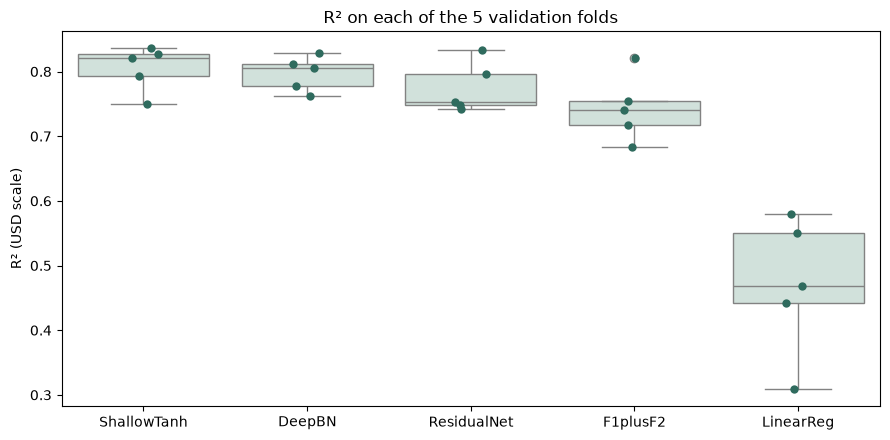

In [12]:
order = list(cv_summary.index)
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=cv, x='model', y='R2', order=order, color='#CFE3DC')
sns.stripplot(data=cv, x='model', y='R2', order=order, color='#2F6B5E', size=6)
plt.title('R² on each of the 5 validation folds'); plt.ylabel('R² (USD scale)'); plt.xlabel('')
plt.tight_layout(); plt.savefig('figures/A_cv_r2.png', dpi=130); plt.show()

## 8. Retrain every model on the full training set and evaluate once on the test set

In [13]:
final_models, loss_curves, test_rows = {}, {}, []
for name in CORES:
    model, losses = train_one(name, U.X_train, U.y_train, verbose=(name == BEST))
    final_models[name], loss_curves[name] = model, losses
    pred = predict_usd(model, U.X_test)
    test_rows.append({'model': name, 'params': sum(p.numel() for p in model.core.parameters()),
                      'test_R2': r2_score(U.y_test, pred),
                      'test_RMSE': mean_squared_error(U.y_test, pred) ** 0.5,
                      'test_MAE': mean_absolute_error(U.y_test, pred),
                      'test_medAPE_%': 100 * np.median(np.abs(pred - U.y_test) / U.y_test)})
results = cv_summary.join(pd.DataFrame(test_rows).set_index('model')).reset_index()
results

  ShallowTanh epoch   0 ..... 0.8118


  ShallowTanh epoch  50 ..... 0.1768


  ShallowTanh epoch 100 ..... 0.1656


  ShallowTanh epoch 150 ..... 0.1639


,model,cv_R2_mean,cv_R2_std,cv_RMSE_mean,params,test_R2,test_RMSE,test_MAE,test_medAPE_%
0,ShallowTanh,0.805400,0.034833,5120.331351,353,0.885603,4584.884077,2397.621826,13.078220
1,DeepBN,0.797125,0.026830,5236.216482,7169,0.882216,4652.267619,2510.852051,10.003567
2,ResidualNet,0.774169,0.039465,5511.265884,5505,0.849544,5258.056295,2608.867920,8.217488
3,F1plusF2,0.743440,0.051001,5860.086098,121,0.843395,5364.432496,3084.859863,18.927715
4,LinearReg,0.469877,0.105982,8434.255650,10,0.718107,7197.196676,3755.760742,13.343451


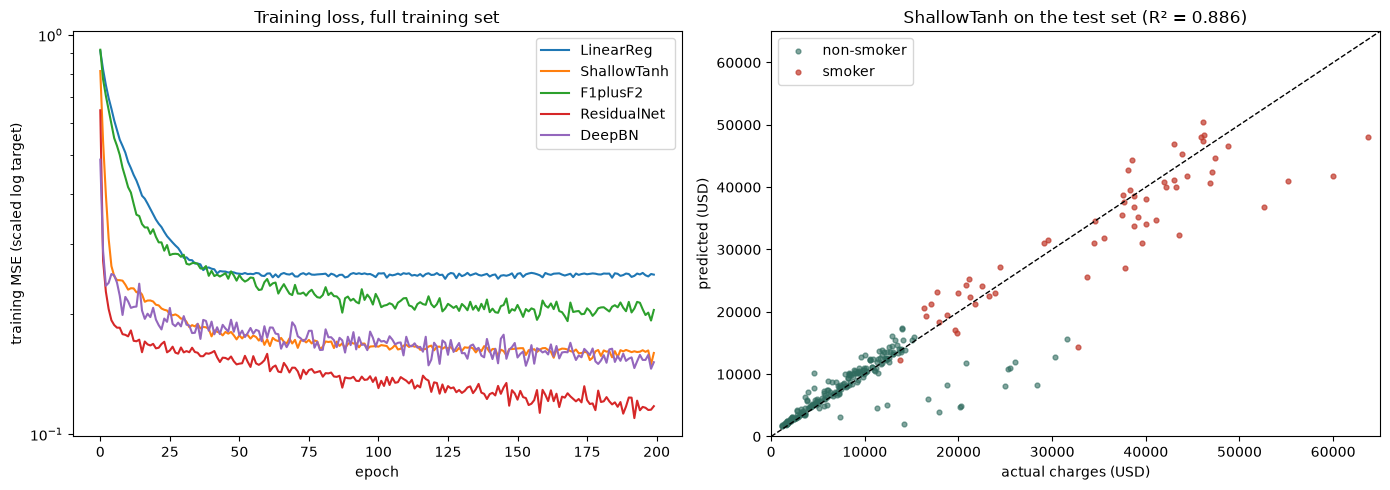

In [14]:
best_model = final_models[BEST]
pred_best  = predict_usd(best_model, U.X_test)
smoker_te  = U.X_test[:, FEATURES.index('smoker_yes')] == 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, l in loss_curves.items():
    axes[0].plot(l, label=name)
axes[0].set_yscale('log'); axes[0].set_xlabel('epoch'); axes[0].set_ylabel('training MSE (scaled log target)')
axes[0].set_title('Training loss, full training set'); axes[0].legend()

axes[1].scatter(U.y_test[~smoker_te], pred_best[~smoker_te], s=12, alpha=0.6, c='#2F6B5E', label='non-smoker')
axes[1].scatter(U.y_test[smoker_te],  pred_best[smoker_te],  s=12, alpha=0.7, c='#C0392B', label='smoker')
lim = [0, 65000]; axes[1].plot(lim, lim, 'k--', lw=1); axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel('actual charges (USD)'); axes[1].set_ylabel('predicted (USD)')
axes[1].set_title(f'{BEST} on the test set (R² = {r2_score(U.y_test, pred_best):.3f})'); axes[1].legend()
plt.tight_layout(); plt.savefig('figures/A_results.png', dpi=130); plt.show()

## 9. Analysis

In [15]:
## (a) Ablation: is the log target worth it? Same architecture, trained on raw USD instead.
U.log_target = False
model_raw, _ = train_one(BEST, U.X_train, U.y_train)
pred_raw = predict_usd(model_raw, U.X_test)
U.log_target = True

def summary(p):
    return {'R2': r2_score(U.y_test, p), 'MAE': mean_absolute_error(U.y_test, p),
            'median_APE_%': 100 * np.median(np.abs(p - U.y_test) / U.y_test)}
ablation = pd.DataFrame({'log target (deployed)': summary(pred_best), 'raw USD target': summary(pred_raw)}).T
ablation

,R2,MAE,median_APE_%
log target (deployed),0.885603,2397.621826,13.07822
raw USD target,0.889717,2780.384277,19.44639


In [16]:
## (b) Effect of smoking: predict every test person twice, as a smoker and as a non-smoker
Xs, Xn = U.X_test.copy(), U.X_test.copy()
Xs[:, FEATURES.index('smoker_yes')] = 1
Xn[:, FEATURES.index('smoker_yes')] = 0
ps, pn = predict_usd(best_model, Xs).ravel(), predict_usd(best_model, Xn).ravel()
print(f'average predicted charges if smoker:     ${ps.mean():,.0f}')
print(f'average predicted charges if non-smoker: ${pn.mean():,.0f}')
print(f'smoking multiplies predicted charges by {np.median(ps / pn):.2f} (median over test people)')

## (c) where the errors are
err = np.abs(pred_best.ravel() - U.y_test.ravel())
print(f'\nMAE non-smokers: ${err[~smoker_te].mean():,.0f} | MAE smokers: ${err[smoker_te].mean():,.0f}')

average predicted charges if smoker:     $32,525
average predicted charges if non-smoker: $7,846
smoking multiplies predicted charges by 4.27 (median over test people)

MAE non-smokers: $1,853 | MAE smokers: $4,286


## 10. Export the selected model to ONNX

The exported graph takes the 9 raw inputs in `FEATURES` order and returns charges in USD. Standardization, de-scaling and the `exp` back-transform are all inside the graph.

In [17]:
class ExportWrapper(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x)[0]

export_model = ExportWrapper(copy.deepcopy(best_model).to('cpu')).eval().float()
dummy_input  = torch.tensor(U.X_test[:1], dtype=torch.float32)
ONNX_PATH = 'ONNXmodels/insurance_charges.onnx'

torch.onnx.export(
    export_model,
    dummy_input,
    ONNX_PATH,
    input_names=['input1'],
    output_names=['output1'],
    opset_version=15,
    do_constant_folding=True,
    dynamic_axes={'input1': {0: 'batch'}, 'output1': {0: 'batch'}},
    dynamo=False,
)
print('saved', ONNX_PATH, f'({os.path.getsize(ONNX_PATH) / 1024:.1f} KB)')

/tmp/ipykernel_98/3103028536.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


saved ONNXmodels/insurance_charges.onnx (2.4 KB)


In [18]:
sess = rt.InferenceSession(ONNX_PATH)
print('input :', [(i.name, i.shape) for i in sess.get_inputs()])
print('output:', [(o.name, o.shape) for o in sess.get_outputs()])
onnx_pred = sess.run(['output1'], {'input1': U.X_test.astype(np.float32)})[0]
print('max |ONNX - PyTorch| =', float(np.abs(onnx_pred - pred_best).max()), 'USD')
print('ONNX test R2 =', r2_score(U.y_test, onnx_pred))

input : [('input1', ['batch', 9])]
output: [('output1', ['batch', 1])]
max |ONNX - PyTorch| = 0.0390625 USD
ONNX test R2 = 0.8856028914451599


In [19]:
def decode(row):
    return {'age': int(row[0]), 'bmi': round(float(row[1]), 3), 'children': int(row[2]),
            'sex': 'male' if row[3] == 1 else 'female', 'smoker': 'yes' if row[4] == 1 else 'no',
            'region': REGIONS[int(np.argmax(row[5:9]))]}

idx = [int(np.where(~smoker_te)[0][0]), int(np.where(smoker_te)[0][0]), int(np.where(~smoker_te)[0][1])]
samples = [{'inputs': decode(U.X_test[i]), 'actual': float(U.y_test[i, 0]), 'onnx_pred': float(onnx_pred[i, 0])} for i in idx]
for s in samples:
    print(s)

summary_out = {'best_model': BEST, 'features': FEATURES, 'regions': REGIONS,
               'cv_and_test': results.to_dict(orient='records'), 'cv_folds': cv.to_dict(orient='records'),
               'ablation': ablation.reset_index().to_dict(orient='records'),
               'smoker_mean_if_yes': float(ps.mean()), 'smoker_mean_if_no': float(pn.mean()),
               'smoker_multiplier_median': float(np.median(ps / pn)),
               'mae_nonsmokers': float(err[~smoker_te].mean()), 'mae_smokers': float(err[smoker_te].mean()),
               'n_train': int(len(U.X_train)), 'n_test': int(len(U.X_test)), 'samples': samples}
with open('ONNXmodels/regression_results.json', 'w') as f:
    json.dump(summary_out, f, indent=2, default=float)
print('saved ONNXmodels/regression_results.json')

{'inputs': {'age': 49, 'bmi': 22.515, 'children': 0, 'sex': 'male', 'smoker': 'no', 'region': 'northeast'}, 'actual': 8688.8583984375, 'onnx_pred': 9622.044921875}
{'inputs': {'age': 31, 'bmi': 34.39, 'children': 3, 'sex': 'male', 'smoker': 'yes', 'region': 'northwest'}, 'actual': 38746.35546875, 'onnx_pred': 33709.15234375}
{'inputs': {'age': 29, 'bmi': 25.6, 'children': 4, 'sex': 'female', 'smoker': 'no', 'region': 'southwest'}, 'actual': 5708.8671875, 'onnx_pred': 5944.046875}
saved ONNXmodels/regression_results.json
